# DATA3001 RQ2 — Optimised FNN: sensitivity and Core retraining

This notebook evaluates the **optimised RQ1 FNN**, not the older six-model RQ2 `FNN` column. It uses the fixed RQ1 training/calibration/test drifter split. Run from the project root or any project subfolder. All files written here stay in `RQ2/data/optimised_fnn_analysis` and `RQ2/figures/optimised_fnn_analysis`.


## 0. Inputs and provenance

Required for sensitivity: `output/rq1/zh/optimised_fnn_test_case_metrics.csv`, `RQ2/data/forecast_case_regimes.csv`, and ideally `RQ2/data/glorys_climatology_1994_2022.nc`. If the grid is absent, the notebook uses the existing case labels from `RQ2/16b_regime_sensitivity.py` and **marks them as precomputed**, so it does not claim a fresh grid recomputation.

Regional retraining additionally requires `data/processed/forecast_origins.parquet` and `region_A_observations.parquet`. The original RQ1 run's saved selection is 128–64 direct, L2 0.001, learning rate 0.001, batch 256, 129 epochs, seeds 2026/2037/2048. The selected config is also visible in cell 9 of `11_optimised_fnn_CN.ipynb`. Missing inputs cause a labelled skip, not invented results.


In [27]:
from pathlib import Path
import copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.ndimage import label
from scipy.spatial import cKDTree

from pathlib import Path


BASE = Path("/Users/zudemac/Desktop/data3001")
ROOT = BASE / "data3001-group-project-main"

DATA = ROOT / "RQ2" / "data"
OUT = DATA / "optimised_fnn_analysis"
FIG = ROOT / "RQ2" / "figures" / "optimised_fnn_analysis"

CLIM = DATA / "glorys_climatology_1994_2022.nc"
SAVED_LABELS = DATA / "rq2_sensitivity_case_labels.csv"
REGIMES = DATA / "forecast_case_regimes.csv"

OPT_ERRORS = ROOT / "output/rq1/zh/optimised_fnn_test_case_metrics.csv"

# These two files are in the outer data3001 folder
ORIGINS = BASE / "processed/forecast_origins.parquet"
OBS = BASE / "processed/region_A_observations.parquet"

N_BOOT = 2000
SEED = 3001
SPEED_THRESHOLDS = (0.4, 0.5, 0.6)
BUFFERS_KM = (25, 50, 75)

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

inputs = pd.DataFrame({
    "input": [
        str(p) for p in
        [CLIM, SAVED_LABELS, REGIMES, OPT_ERRORS, ORIGINS, OBS]
    ],
    "available": [
        p.is_file() for p in
        [CLIM, SAVED_LABELS, REGIMES, OPT_ERRORS, ORIGINS, OBS]
    ]
})

print("Project root:", ROOT)
print("RQ2 exists:", (ROOT / "RQ2").is_dir())
display(inputs)

if not REGIMES.is_file() or not OPT_ERRORS.is_file() or not (
    CLIM.is_file() or SAVED_LABELS.is_file()
):
    raise FileNotFoundError(
        "Missing required sensitivity analysis inputs."
    )

Project root: /Users/zudemac/Desktop/data3001/data3001-group-project-main
RQ2 exists: True


,input,available
0,/Users/zudemac/Desktop/data3001/data3001-group...,False
1,/Users/zudemac/Desktop/data3001/data3001-group...,True
2,/Users/zudemac/Desktop/data3001/data3001-group...,True
3,/Users/zudemac/Desktop/data3001/data3001-group...,True
4,/Users/zudemac/Desktop/data3001/processed/fore...,True
5,/Users/zudemac/Desktop/data3001/processed/regi...,True


## 1. Load the same 757 test cases

Join by `forecast_case_id`, verify drifter identity and finite nonnegative 72h errors. The old `RQ2/data/rq2_test_model_errors_long.csv` uses an earlier FNN and is deliberately not used here.

In [28]:
reg = pd.read_csv(REGIMES)
opt = pd.read_csv(OPT_ERRORS)
assert reg.forecast_case_id.is_unique and opt.forecast_case_id.is_unique
assert {'forecast_case_id','ID','partition','origin_longitude','origin_latitude','depth_m','regime','glorys_match_valid'} <= set(reg)
assert {'forecast_case_id','drifter_id','error_72h_km'} <= set(opt)
cases = reg.loc[reg.partition.eq('test')].merge(opt[['forecast_case_id','drifter_id','error_72h_km']], on='forecast_case_id',validate='one_to_one',indicator=True).sort_values('forecast_case_id').reset_index(drop=True)
assert len(cases)==len(opt)==757 and cases._merge.eq('both').all()
assert (cases.ID.astype(str)==cases.drifter_id.astype(str)).all()
assert cases.ID.nunique()==71
assert cases.glorys_match_valid.fillna(False).astype(bool).all()
assert np.isfinite(cases[['origin_longitude','origin_latitude','depth_m','error_72h_km']].to_numpy(float)).all()
assert cases.depth_m.ge(0).all() and cases.error_72h_km.ge(0).all()
print('Optimised FNN:',len(cases),'test cases;',cases.ID.nunique(),'drifters')

Optimised FNN: 757 test cases; 71 drifters


## 2. Reclassify physical regimes

GLORYS uses speed $\sqrt{u^2+v^2}$; at each threshold, 8-neighbour components are labelled and the **two largest** are the Core. A case matches the nearest wet grid cell (≤15 km). GEBCO `depth_m` from the existing case table gives Shelf ≤200 m; otherwise Transition if depth ≤1000 m or distance to Core ≤buffer; remaining cases are Other Offshore. Priority: Core → Shelf → Transition → Other Offshore. The 0.5 m/s, 50 km labels must exactly reproduce the saved main classification.


In [29]:
def xyz(lon,lat):
    lon,lat=np.deg2rad(np.asarray(lon,float)),np.deg2rad(np.asarray(lat,float))
    return np.column_stack((np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)))
def chord_km(chord):
    return 2*6371.0088*np.arcsin(np.clip(np.asarray(chord)/2,0,1))
def recompute_labels(cases, path):
    import xarray as xr
    with xr.open_dataset(path) as ds:
        u=ds['u_mean'].squeeze(drop=True).transpose('latitude','longitude').values
        v=ds['v_mean'].squeeze(drop=True).transpose('latitude','longitude').values
        lon,lat=ds.longitude.values,ds.latitude.values
    speed=np.hypot(u,v); wet=np.isfinite(speed)
    lg,ag=np.meshgrid(lon,lat)
    wet_tree=cKDTree(xyz(lg[wet],ag[wet]))
    d,ix=wet_tree.query(xyz(cases.origin_longitude,cases.origin_latitude))
    assert chord_km(d).max()<=15, 'GLORYS match exceeds 15 km'
    rr,cc=np.unravel_index(np.flatnonzero(wet)[ix],wet.shape)
    rows=[]
    for threshold in SPEED_THRESHOLDS:
        components,_=label(wet & (speed>=threshold),structure=np.ones((3,3),int))
        sizes=np.bincount(components.ravel()); sizes[0]=0
        if len(sizes)<3: raise ValueError(f'Fewer than two current components at {threshold}')
        top2=np.argsort(sizes)[-2:][::-1]
        core_grid=np.isin(components,top2)
        core_tree=cKDTree(xyz(lg[core_grid],ag[core_grid]))
        distance=chord_km(core_tree.query(xyz(cases.origin_longitude,cases.origin_latitude))[0])
        is_core=core_grid[rr,cc]
        for buffer in BUFFERS_KM:
            shelf=(~is_core)&(cases.depth_m.to_numpy()<=200)
            transition=(~is_core)&(~shelf)&((cases.depth_m.to_numpy()<=1000)|(distance<=buffer))
            regimes=np.full(len(cases),'Other Offshore',dtype=object)
            regimes[transition]='Transition'; regimes[shelf]='Shelf'; regimes[is_core]='Kuroshio Core'
            rows.append(pd.DataFrame({'forecast_case_id':cases.forecast_case_id,'ID':cases.ID,'speed_threshold_m_s':threshold,'buffer_km':buffer,'regime':regimes,'distance_to_core_km':distance}))
    return pd.concat(rows,ignore_index=True)

if CLIM.is_file():
    labels=recompute_labels(cases,CLIM)
    label_source='fresh GLORYS grid recomputation'
    if SAVED_LABELS.is_file():
        old=pd.read_csv(SAVED_LABELS)
        check=labels.merge(old[['forecast_case_id','speed_threshold_m_s','buffer_km','regime']],on=['forecast_case_id','speed_threshold_m_s','buffer_km'],suffixes=('_new','_saved'),validate='one_to_one')
        print('Saved sensitivity label agreement:',(check.regime_new==check.regime_saved).mean())
else:
    labels=pd.read_csv(SAVED_LABELS)
    label_source='precomputed RQ2/16b_regime_sensitivity.py labels; GLORYS grid unavailable'
required={'forecast_case_id','ID','speed_threshold_m_s','buffer_km','regime'}
assert required<=set(labels)
assert not labels.duplicated(['forecast_case_id','speed_threshold_m_s','buffer_km']).any()
assert len(labels)==len(cases)*9
assert set(labels.forecast_case_id)==set(cases.forecast_case_id)
assert set(zip(labels.speed_threshold_m_s,labels.buffer_km))=={(a,b) for a in SPEED_THRESHOLDS for b in BUFFERS_KM}
main=labels.loc[np.isclose(labels.speed_threshold_m_s,.5)&labels.buffer_km.eq(50)].sort_values('forecast_case_id')
assert np.array_equal(main.regime.to_numpy(),cases.regime.to_numpy()), '0.5 m/s, 50 km fails to reproduce RQ2 main labels'
assert (main.ID.astype(str).to_numpy()==cases.ID.astype(str).to_numpy()).all()
print('Label source:',label_source)
print('Main setting reproduces all',len(main),'labels')

Label source: precomputed RQ2/16b_regime_sensitivity.py labels; GLORYS grid unavailable
Main setting reproduces all 757 labels


## 3. Core−Shelf 72h endpoint errors

For each setting, report median and RMSE of the **same fixed global Optimised FNN** errors in newly assigned Core and Shelf cases. Difference = metric(Core) − metric(Shelf), in km. Bootstrap resamples drifter IDs with replacement, carrying all their cases together; the same sampled IDs are used across settings. CI is percentile 95%.

In [30]:
joined=labels.merge(cases[['forecast_case_id','ID','error_72h_km']],on='forecast_case_id',suffixes=('_label',''),validate='many_to_one')
assert (joined.ID_label.astype(str)==joined.ID.astype(str)).all()
ids=cases.ID.to_numpy(); unique=np.unique(ids)
by_id=[np.flatnonzero(ids==x) for x in unique]
rng=np.random.default_rng(SEED)
draws=rng.integers(0,len(unique),size=(N_BOOT,len(unique)))
boot_indices=[np.concatenate([by_id[j] for j in draw]) for draw in draws]
def rmse(x): return float(np.sqrt(np.mean(np.square(x))))
rows=[]; count_rows=[]
for threshold in SPEED_THRESHOLDS:
 for buffer in BUFFERS_KM:
    setting=joined.loc[np.isclose(joined.speed_threshold_m_s,threshold)&joined.buffer_km.eq(buffer)].sort_values('forecast_case_id')
    assert np.array_equal(setting.forecast_case_id.to_numpy(),cases.forecast_case_id.to_numpy())
    lab=setting.regime.to_numpy(); err=cases.error_72h_km.to_numpy(float)
    core=lab=='Kuroshio Core'; shelf=lab=='Shelf'
    for name in ['Kuroshio Core','Shelf','Transition','Other Offshore']:
        mask=lab==name
        count_rows.append({'threshold_m_s':threshold,'buffer_km':buffer,'regime':name,'n_cases':int(mask.sum()),'n_drifters':int(np.unique(ids[mask]).size)})
    if not core.any() or not shelf.any():
        raise ValueError(f'Empty Core or Shelf at {threshold}, {buffer}')
    reps_med=[]; reps_rmse=[]
    for bi in boot_indices:
        c=err[bi[core[bi]]]; s=err[bi[shelf[bi]]]
        if len(c) and len(s):
            reps_med.append(np.median(c)-np.median(s)); reps_rmse.append(rmse(c)-rmse(s))
    for metric,func,reps in [('median',np.median,reps_med),('rmse',rmse,reps_rmse)]:
        lo,hi=np.percentile(reps,[2.5,97.5]) if reps else (np.nan,np.nan)
        rows.append({'threshold_m_s':threshold,'buffer_km':buffer,'metric':metric,'core_km':float(func(err[core])),'shelf_km':float(func(err[shelf])),'core_minus_shelf_km':float(func(err[core])-func(err[shelf])),'ci_low_km':lo,'ci_high_km':hi,'n_core':int(core.sum()),'n_shelf':int(shelf.sum()),'valid_bootstrap':len(reps),'label_source':label_source})
sensitivity=pd.DataFrame(rows); counts=pd.DataFrame(count_rows)
sensitivity.to_csv(OUT/'sensitivity_optimised_fnn.csv',index=False)
counts.to_csv(OUT/'sensitivity_regime_counts.csv',index=False)
display(sensitivity.round(2))

,threshold_m_s,buffer_km,metric,core_km,shelf_km,core_minus_shelf_km,ci_low_km,ci_high_km,n_core,n_shelf,valid_bootstrap,label_source
0,0.4,25,median,61.22,24.46,36.76,28.59,50.61,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
1,0.4,25,rmse,87.29,36.84,50.46,40.22,60.83,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
2,0.4,50,median,61.22,24.46,36.76,28.59,50.61,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
3,0.4,50,rmse,87.29,36.84,50.46,40.22,60.83,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
4,0.4,75,median,61.22,24.46,36.76,28.59,50.61,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
5,0.4,75,rmse,87.29,36.84,50.46,40.22,60.83,177,108,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
6,0.5,25,median,61.22,24.66,36.55,27.57,52.30,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
7,0.5,25,rmse,85.86,40.83,45.04,31.98,57.33,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
8,0.5,50,median,61.22,24.66,36.55,27.57,52.30,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...
9,0.5,50,rmse,85.86,40.83,45.04,31.98,57.33,139,112,2000,precomputed RQ2/16b_regime_sensitivity.py labe...


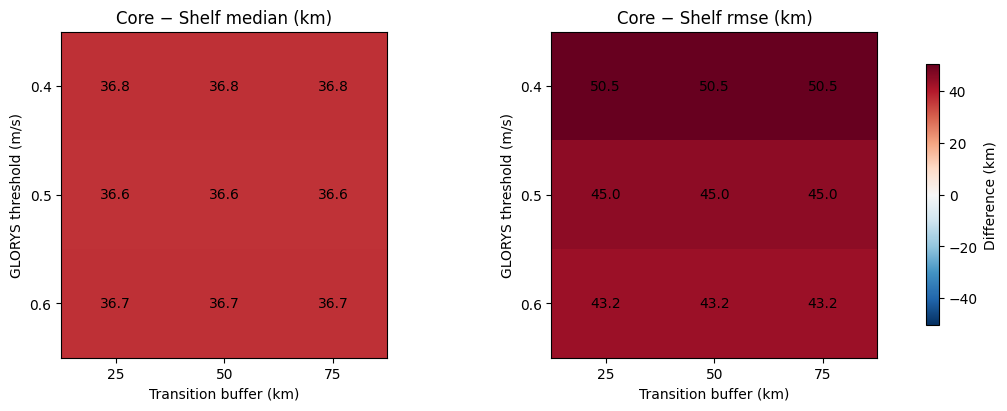

In [31]:
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,metric in zip(axes,['median','rmse']):
    d=sensitivity.loc[sensitivity.metric.eq(metric)]
    grid=d.pivot(index='threshold_m_s',columns='buffer_km',values='core_minus_shelf_km').reindex(index=SPEED_THRESHOLDS,columns=BUFFERS_KM)
    im=ax.imshow(grid.to_numpy(),cmap='RdBu_r',vmin=-max(abs(sensitivity.core_minus_shelf_km)),vmax=max(abs(sensitivity.core_minus_shelf_km)))
    ax.set_xticks(range(3),BUFFERS_KM);ax.set_yticks(range(3),SPEED_THRESHOLDS)
    ax.set_xlabel('Transition buffer (km)');ax.set_ylabel('GLORYS threshold (m/s)');ax.set_title(f'Core − Shelf {metric} (km)')
    for i in range(3):
        for j in range(3): ax.text(j,i,f'{grid.iloc[i,j]:.1f}',ha='center',va='center',color='black')
fig.colorbar(im,ax=axes,label='Difference (km)',shrink=.8)
fig.savefig(FIG/'sensitivity_optimised_fnn.png',dpi=160)
plt.show()

## 4. Regional retraining

Use the **same 98 input features**, 144 output displacements, ReLU network, Adam loss, standardisation fitted on the selected training subset, and the RQ1 selected hyperparameters. `Core-only` means `partition == training` and main-setting `regime == Kuroshio Core`; calibration and test are never used for fitting. The global comparator is the saved Optimised FNN test error file, evaluated on the *identical Core test case IDs*. Retraining all three seeds may take time.


In [32]:
HISTORY_HOURS,HORIZON_HOURS=24,72
MAX_EPOCHS,PATIENCE=160,18
EARTH_RADIUS_KM=6371.0
BEST_CONFIG={'name':'128-64 direct L2','hidden_sizes':(128,64),'l2':1e-3,'learning_rate':1e-3,'batch_size':256,'target_mode':'direct'}
SELECTED_EPOCHS=129
FINAL_SEEDS=[2026,2037,2048]
# Original RQ1 functions are copied verbatim below to make this notebook standalone.
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0, lon0 = np.deg2rad(origin_lat), np.deg2rad(origin_lon)
    lat1, lon1 = np.deg2rad(latitude), np.deg2rad(longitude)
    dlon = (lon1 - lon0 + np.pi) % (2*np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat/2)**2 + np.cos(lat0)*np.cos(lat1)*np.sin(dlon/2)**2
    angle = 2*np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(np.sin(dlon)*np.cos(lat1),
                         np.cos(lat0)*np.sin(lat1)-np.sin(lat0)*np.cos(lat1)*np.cos(dlon))
    distance = EARTH_RADIUS_KM * angle
    return distance*np.sin(bearing), distance*np.cos(bearing)

def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0, lon0 = np.deg2rad(origin_lat), np.deg2rad(origin_lon)
    distance = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular = distance / EARTH_RADIUS_KM
    lat = np.arcsin(np.sin(lat0)*np.cos(angular)+np.cos(lat0)*np.sin(angular)*np.cos(bearing))
    lon = lon0 + np.arctan2(np.sin(bearing)*np.sin(angular)*np.cos(lat0),
                            np.cos(angular)-np.sin(lat0)*np.sin(lat))
    return np.rad2deg(lat), (np.rad2deg(lon)+180)%360-180

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.deg2rad, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def initialise(layer_sizes, rng):
    return [{'W':rng.normal(0,np.sqrt(2/fan_in),(fan_in,fan_out)), 'b':np.zeros(fan_out)}
            for fan_in,fan_out in zip(layer_sizes[:-1],layer_sizes[1:])]

def forward(parameters, Xb):
    acts, zs, cur = [Xb], [], Xb
    for j, layer in enumerate(parameters):
        z = cur@layer['W'] + layer['b']; zs.append(z)
        cur = np.maximum(z,0) if j < len(parameters)-1 else z
        acts.append(cur)
    return cur, acts, zs

def loss_and_grads(parameters, Xb, Yb, l2):
    pred, acts, zs = forward(parameters,Xb)
    residual = pred-Yb
    # Keep the original objective: standardised MSE + lambda * sum(W^2)
    loss = np.mean(residual**2) + l2*sum(np.sum(p['W']**2) for p in parameters)
    delta = 2*residual/residual.size
    grads = [None]*len(parameters)
    for j in range(len(parameters)-1,-1,-1):
        grads[j] = {'W':acts[j].T@delta + 2*l2*parameters[j]['W'], 'b':delta.sum(0)}
        if j>0: delta = (delta@parameters[j]['W'].T)*(zs[j-1]>0)
    return loss, grads

def endpoint_errors(pred_abs, true_abs, origin_rows):
    p = pred_abs.reshape(-1,72,2)[:,-1,:]
    y = true_abs.reshape(-1,72,2)[:,-1,:]
    olat = origin_rows.origin_latitude.to_numpy(); olon = origin_rows.origin_longitude.to_numpy()
    plat,plon = local_km_to_latlon(olat,olon,p[:,0],p[:,1])
    tlat,tlon = local_km_to_latlon(olat,olon,y[:,0],y[:,1])
    return haversine_km(plat,plon,tlat,tlon)

def fit_fnn(Xtr_raw, Ytr_model, Xva_raw, Yva_model, Yva_abs, va_origins,
            offset_valid, config, seed, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    xm, xs = Xtr_raw.mean(0), Xtr_raw.std(0); xs[xs<1e-12]=1
    ym, ys = Ytr_model.mean(0), Ytr_model.std(0); ys[ys<1e-12]=1
    Xtr=(Xtr_raw-xm)/xs; Ytr=(Ytr_model-ym)/ys; Xva=(Xva_raw-xm)/xs
    rng=np.random.default_rng(seed)
    params=initialise((98,*config['hidden_sizes'],144),rng)
    m=[{'W':np.zeros_like(p['W']),'b':np.zeros_like(p['b'])} for p in params]
    v=copy.deepcopy(m); step=0; best=np.inf; best_epoch=0; best_params=None; stale=0; rows=[]
    for epoch in range(1,max_epochs+1):
        losses=[]
        permutation=rng.permutation(len(Xtr))
        for start in range(0,len(Xtr),config['batch_size']):
            batch=permutation[start:start+config['batch_size']]
            loss,grads=loss_and_grads(params,Xtr[batch],Ytr[batch],config['l2']); losses.append(loss); step+=1
            for j,(p,g) in enumerate(zip(params,grads)):
                for key in ('W','b'):
                    m[j][key]=.9*m[j][key]+.1*g[key]
                    v[j][key]=.999*v[j][key]+.001*g[key]**2
                    mh=m[j][key]/(1-.9**step); vh=v[j][key]/(1-.999**step)
                    p[key]-=config['learning_rate']*mh/(np.sqrt(vh)+1e-8)
        pred_model=forward(params,Xva)[0]*ys+ym
        pred_abs=pred_model+offset_valid
        rmse=float(np.sqrt(np.mean(endpoint_errors(pred_abs,Yva_abs,va_origins)**2)))
        rows.append({'epoch':epoch,'training_objective':float(np.mean(losses)),'validation_72h_rmse_km':rmse})
        if rmse < best-1e-4:
            best,best_epoch,best_params,stale=rmse,epoch,copy.deepcopy(params),0
        else: stale+=1
        if stale>=patience: break
    return dict(parameters=best_params,x_mean=xm,x_scale=xs,y_mean=ym,y_scale=ys,
                best_epoch=best_epoch,best_rmse=best,history=pd.DataFrame(rows))

def predict_model(model,Xnew):
    z=(Xnew-model['x_mean'])/model['x_scale']
    return forward(model['parameters'],z)[0]*model['y_scale']+model['y_mean']

def fit_final(Xraw,Ymodel,config,epochs,seed):
    xm,xs=Xraw.mean(0),Xraw.std(0); xs[xs<1e-12]=1
    ym,ys=Ymodel.mean(0),Ymodel.std(0); ys[ys<1e-12]=1
    Xtr=(Xraw-xm)/xs; Ytr=(Ymodel-ym)/ys; rng=np.random.default_rng(seed)
    params=initialise((98,*config['hidden_sizes'],144),rng)
    m=[{'W':np.zeros_like(p['W']),'b':np.zeros_like(p['b'])} for p in params]; v=copy.deepcopy(m); step=0
    for epoch in range(epochs):
        perm=rng.permutation(len(Xtr))
        for start in range(0,len(Xtr),config['batch_size']):
            batch=perm[start:start+config['batch_size']]
            _,grads=loss_and_grads(params,Xtr[batch],Ytr[batch],config['l2']); step+=1
            for j,(p,g) in enumerate(zip(params,grads)):
                for key in ('W','b'):
                    m[j][key]=.9*m[j][key]+.1*g[key]; v[j][key]=.999*v[j][key]+.001*g[key]**2
                    p[key]-=config['learning_rate']*(m[j][key]/(1-.9**step))/(np.sqrt(v[j][key]/(1-.999**step))+1e-8)
    return dict(parameters=params,x_mean=xm,x_scale=xs,y_mean=ym,y_scale=ys)

In [33]:
regional_ready=ORIGINS.is_file() and OBS.is_file()
if not regional_ready:
    print('REGIONAL RETRAINING SKIPPED. Missing:')
    for p in [ORIGINS,OBS]:
        if not p.is_file(): print(' -',p.relative_to(ROOT))
else:
    origins=pd.read_parquet(ORIGINS).sort_values('forecast_case_id').reset_index(drop=True)
    observations=pd.read_parquet(OBS,columns=['ID','segment_id','segment_step','time','latitude','longitude','ve','vn'])
    n_cases=len(origins)
    history=origins[['forecast_case_id','ID','segment_id','history_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
    history['history_index']=np.tile(np.arange(HISTORY_HOURS),n_cases)
    history['segment_step']=history.history_start_step+history.history_index
    history=history.merge(observations,on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','history_index']).reset_index(drop=True)
    history['relative_east_km'],history['relative_north_km']=latlon_to_local_km(history.origin_latitude,history.origin_longitude,history.latitude,history.longitude)
    hv=history[['relative_east_km','relative_north_km','ve','vn']].to_numpy().reshape(n_cases,24,4)
    X=np.column_stack([origins.origin_latitude,origins.origin_longitude,hv.reshape(n_cases,-1)]).astype(float)
    targets=origins[['forecast_case_id','ID','segment_id','target_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
    targets['lead_time_hours']=np.tile(np.arange(1,73),n_cases)
    targets['segment_step']=targets.target_start_step+targets.lead_time_hours-1
    targets=targets.merge(observations[['ID','segment_id','segment_step','latitude','longitude']],on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','lead_time_hours']).reset_index(drop=True)
    targets['target_east_km'],targets['target_north_km']=latlon_to_local_km(targets.origin_latitude,targets.origin_longitude,targets.latitude,targets.longitude)
    Y=targets[['target_east_km','target_north_km']].to_numpy().reshape(n_cases,144).astype(float)
    assert X.shape==(5117,98) and Y.shape==(5117,144) and np.isfinite(X).all() and np.isfinite(Y).all()
    annotated=origins.merge(reg[['forecast_case_id','ID','partition','regime']],on='forecast_case_id',suffixes=('','_reg'),validate='one_to_one')
    assert (annotated.ID.astype(str)==annotated.ID_reg.astype(str)).all()
    assert (annotated.partition==annotated.partition_reg).all()
    core_train=np.flatnonzero(annotated.partition.eq('training')&annotated.regime.eq('Kuroshio Core'))
    core_test=np.flatnonzero(annotated.partition.eq('test')&annotated.regime.eq('Kuroshio Core'))
    assert len(core_train)>0 and len(core_test)>0
    assert set(annotated.loc[core_test,'forecast_case_id'])==set(cases.loc[cases.regime.eq('Kuroshio Core'),'forecast_case_id'])
    print('Core training:',len(core_train),'cases,',annotated.loc[core_train,'ID'].nunique(),'drifters; test:',len(core_test),'cases')

Core training: 646 cases, 208 drifters; test: 139 cases


In [34]:
if regional_ready:
    predictions=[]
    for seed in FINAL_SEEDS:
        model=fit_final(X[core_train],Y[core_train],BEST_CONFIG,SELECTED_EPOCHS,seed)
        predictions.append(predict_model(model,X[core_test]))
    pred=np.mean(predictions,axis=0)
    regional_error=endpoint_errors(pred,Y[core_test],origins.loc[core_test])
    result=annotated.loc[core_test,['forecast_case_id','ID']].copy().reset_index(drop=True)
    result['regional_error_72h_km']=regional_error
    result=result.merge(opt[['forecast_case_id','error_72h_km']],on='forecast_case_id',validate='one_to_one').rename(columns={'error_72h_km':'global_error_72h_km'})
    assert len(result)==len(core_test) and result.forecast_case_id.is_unique
    result.to_csv(OUT/'core_test_global_vs_regional_optimised_fnn.csv',index=False)
    print('Saved case-level comparison:',OUT/'core_test_global_vs_regional_optimised_fnn.csv')

Saved case-level comparison: /Users/zudemac/Desktop/data3001/data3001-group-project-main/RQ2/data/optimised_fnn_analysis/core_test_global_vs_regional_optimised_fnn.csv


## 5. Paired comparison and uncertainty

Both models are scored on exactly the same Core test origins. We report median and RMSE of 72h endpoint error, with Global−Regional differences. For each bootstrap replicate, sample Core test drifters with replacement and carry paired case errors together.

,metric,global_km,regional_km,global_minus_regional_km,ci_low_km,ci_high_km,n_cases,n_drifters,valid_bootstrap
0,median,61.22,62.17,-0.95,-6.44,10.49,139,45,2000
1,rmse,85.86,82.12,3.74,0.60,6.85,139,45,2000


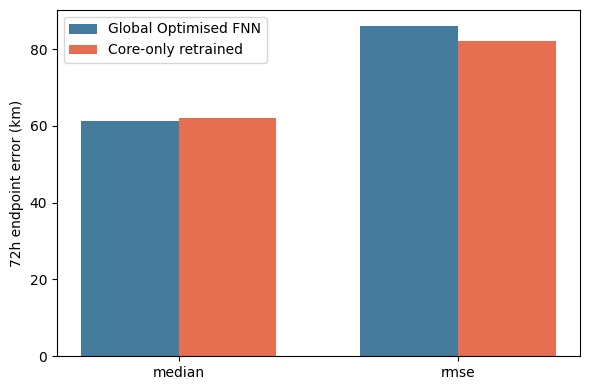

In [35]:
if regional_ready:
    g=result.global_error_72h_km.to_numpy(float); r=result.regional_error_72h_km.to_numpy(float)
    groups=result.ID.to_numpy(); uniq=np.unique(groups); idx=[np.flatnonzero(groups==x) for x in uniq]
    rng=np.random.default_rng(SEED)
    draws=rng.integers(0,len(uniq),size=(N_BOOT,len(uniq)))
    comparison=[]
    for metric,func in [('median',np.median),('rmse',rmse)]:
        reps=[float(func(g[bi])-func(r[bi])) for draw in draws for bi in [np.concatenate([idx[j] for j in draw])]]
        lo,hi=np.percentile(reps,[2.5,97.5])
        comparison.append({'metric':metric,'global_km':float(func(g)),'regional_km':float(func(r)),'global_minus_regional_km':float(func(g)-func(r)),'ci_low_km':lo,'ci_high_km':hi,'n_cases':len(result),'n_drifters':len(uniq),'valid_bootstrap':len(reps)})
    comparison=pd.DataFrame(comparison)
    comparison.to_csv(OUT/'core_retraining_comparison.csv',index=False)
    display(comparison.round(2))
    fig,ax=plt.subplots(figsize=(6,4))
    x=np.arange(2);width=.35
    ax.bar(x-width/2,comparison.global_km,width,label='Global Optimised FNN',color='#457B9D')
    ax.bar(x+width/2,comparison.regional_km,width,label='Core-only retrained',color='#E76F51')
    ax.set_xticks(x,comparison.metric);ax.set_ylabel('72h endpoint error (km)');ax.legend()
    fig.tight_layout();fig.savefig(FIG/'core_retraining_comparison.png',dpi=160);plt.show()
else:
    print('No regional performance values: source trajectory parquet files are unavailable.')

### PPT-ready horizontal comparison

The chart below uses the paired Core-test comparison calculated above when available. If the retraining inputs are missing, it reads the saved comparison table; otherwise it uses the four values supplied for the presentation (RMSE: 85.86 vs 82.12 km; median: 61.22 vs 62.17 km). The source is printed when the cell runs. PNG and SVG files are saved in `RQ2/figures/optimised_fnn_analysis`.


Chart data source: calculated from this notebook run
Saved: /Users/zudemac/Desktop/figure/core_retraining_comparison_horizontal.png
Saved: /Users/zudemac/Desktop/figure/core_retraining_comparison_horizontal.svg


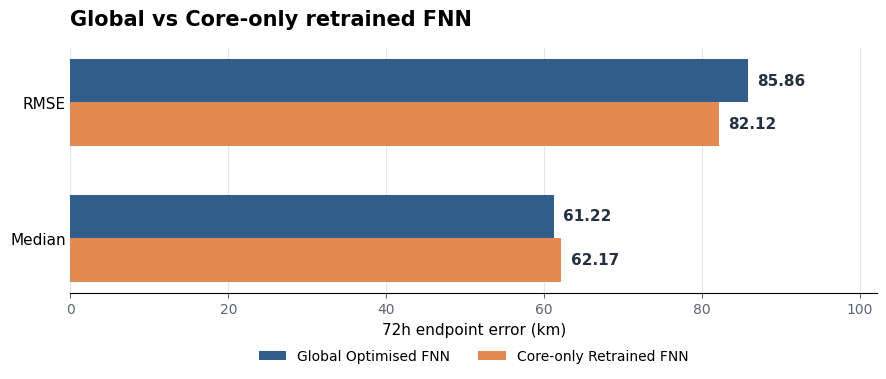

In [38]:
# Prefer metrics calculated on the same Core test cases in this notebook.
chart_csv = OUT / 'core_retraining_comparison.csv'
if regional_ready and 'comparison' in globals():
    chart_data = comparison.copy()
    chart_source = 'calculated from this notebook run'
elif chart_csv.is_file():
    chart_data = pd.read_csv(chart_csv)
    chart_source = f'saved comparison table: {chart_csv.relative_to(ROOT)}'
else:
    chart_data = pd.DataFrame({
        'metric': ['rmse', 'median'],
        'global_km': [85.86, 61.22],
        'regional_km': [82.12, 62.17],
    })
    chart_source = 'presentation values supplied by the user; retraining inputs unavailable'

chart_data = chart_data.set_index('metric').loc[['rmse', 'median']]
values = chart_data[['global_km', 'regional_km']].astype(float)
assert np.isfinite(values.to_numpy()).all() and values.ge(0).all().all()

fig, ax = plt.subplots(figsize=(9.6, 4.3), facecolor='white')
y = np.arange(2)
bar_height = 0.32
colors = {'global_km': '#315D8A', 'regional_km': '#E28A52'}
for column, offset, label in [
    ('global_km', -bar_height / 2, 'Global Optimised FNN'),
    ('regional_km', bar_height / 2, 'Core-only Retrained FNN'),
]:
    bars = ax.barh(y + offset, values[column], height=bar_height,
                   color=colors[column], label=label)
    for bar, value in zip(bars, values[column]):
        ax.text(value + 1.2, bar.get_y() + bar.get_height() / 2,
                f'{value:.2f}', va='center', ha='left', fontsize=11,
                fontweight='semibold', color='#243142')

ax.set_yticks(y, ['RMSE', 'Median'])
ax.invert_yaxis()
ax.set_xlim(0, values.to_numpy().max() * 1.19)
ax.set_xlabel('72h endpoint error (km)', fontsize=11)
ax.set_title('Global vs Core-only retrained FNN', loc='left',
             fontsize=15, fontweight='bold', pad=16)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18),
          ncol=2, frameon=False, fontsize=10)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=11)
ax.tick_params(axis='x', colors='#5B6573')
ax.grid(axis='x', color='#DFE5EA', linewidth=0.8)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.13, right=0.97, top=0.82, bottom=0.25)

from pathlib import Path

FIG = Path.home() / "Desktop" / "figure"
FIG.mkdir(parents=True, exist_ok=True)

png_path = FIG / "core_retraining_comparison_horizontal.png"
svg_path = FIG / "core_retraining_comparison_horizontal.svg"

fig.savefig(png_path, dpi=300, facecolor="white", bbox_inches="tight")
fig.savefig(svg_path, facecolor="white", bbox_inches="tight")

print("Chart data source:", chart_source)
print("Saved:", png_path)
print("Saved:", svg_path)

plt.show()

## Reading the results

- Sensitivity table: Core−Shelf is a **difference of two group summaries**, not an individual travel distance or buffer distance. A positive number means the optimised global FNN has larger Core error. RMSE gives greater weight to large errors.
- Regional table: Global−Regional >0 means Core-only retraining improved the metric on identical Core cases. If a percentile CI spans zero, the observed direction is uncertain under drifter resampling.
- These are endpoint errors at 72h. The 25/50/75 **km** values define the spatial Transition buffer around the Core, not forecast errors.
